# Task 1 — Analytics Intern Assignment

This notebook covers Task 1:

1. Data quality
2. Daily health
3. Retention cohorts
4. Spender behaviour
5. Rewarded-ad engagement

**Data quality uses Python.**  
**The four Task 1 analyses use SQL.**

Analysis window: **2026-01-01 to 2026-04-30**.


In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

START_DATE = pd.Timestamp("2026-01-01")
END_DATE = pd.Timestamp("2026-05-01")

# Project root = parent of notebooks/
PROJECT = Path.cwd().parent

SQL_DIR = PROJECT / "sql" / "task-1"
OUTPUT_DIR = PROJECT / "output"
CHART_DIR = OUTPUT_DIR / "charts"
TABLE_DIR = OUTPUT_DIR / "tables"

CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

DB_PATH = PROJECT / "analysis.duckdb"

con = duckdb.connect(str(DB_PATH))

print("Project:", PROJECT)
print("Database:", DB_PATH)

Project: v:\2026\Analytics Intern Assignment
Database: v:\2026\Analytics Intern Assignment\analysis.duckdb


## 0. Load data

The notebook expects the CSV files in `data/`.

If `analysis.duckdb` already contains the tables, this step keeps them.


In [10]:
DATA_DIR = PROJECT / "data"

csv_files = {
    "player_profile": DATA_DIR / "player_profile.csv",
    "player_day": DATA_DIR / "player_day.csv",
    "purchase": DATA_DIR / "purchase.csv",
    "currency_spend": DATA_DIR / "currency_spend.csv",
    "ad_view": DATA_DIR / "ad_view.csv",
}

for table, path in csv_files.items():
    if path.exists():
        con.execute(
            f"CREATE OR REPLACE TABLE {table} AS "
            f"SELECT * FROM read_csv_auto('{path.as_posix()}')"
        )

print("Tables:")
for table in csv_files:
    exists = con.execute(
        "SELECT COUNT(*) FROM information_schema.tables "
        "WHERE table_name = ?",
        [table]
    ).fetchone()[0]
    print(f"{table:18s} {'OK' if exists else 'MISSING'}")


Tables:
player_profile     OK
player_day         OK
purchase           OK
currency_spend     OK
ad_view            OK


## 1. Data quality

The checks below use Python for quick inspection.

We flag issues first and avoid silently deleting records.


In [7]:
tables = [
    "player_profile",
    "player_day",
    "purchase",
    "currency_spend",
    "ad_view",
]

row_counts = pd.DataFrame({
    "table": tables,
    "rows": [
        con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
        for t in tables
    ],
})

display(row_counts)


,table,rows
0,player_profile,80295
1,player_day,667435
2,purchase,15426
3,currency_spend,489892
4,ad_view,647623


In [8]:
player_profile = con.execute("SELECT * FROM player_profile").df()
player_day = con.execute("SELECT * FROM player_day").df()
purchase = con.execute("SELECT * FROM purchase").df()
currency_spend = con.execute("SELECT * FROM currency_spend").df()
ad_view = con.execute("SELECT * FROM ad_view").df()

player_profile["install_date"] = pd.to_datetime(
    player_profile["install_date"], errors="coerce"
)

player_day["activity_date"] = pd.to_datetime(
    player_day["activity_date"].astype(str),
    format="%Y%m%d",
    errors="coerce"
)

purchase["event_ts"] = pd.to_datetime(
    purchase["event_ts"], errors="coerce"
)

currency_spend["event_ts"] = pd.to_datetime(
    currency_spend["event_ts"], errors="coerce"
)

ad_view["event_ts"] = pd.to_datetime(
    ad_view["event_ts"], errors="coerce"
)

print("Dates converted.")


Dates converted.


### 1.1 Missing values

In [9]:
missing = pd.DataFrame({
    "player_profile": player_profile.isna().sum(),
    "player_day": player_day.isna().sum(),
    "purchase": purchase.isna().sum(),
    "currency_spend": currency_spend.isna().sum(),
    "ad_view": ad_view.isna().sum(),
}).fillna(0)

display(missing[missing.sum(axis=1) > 0])


,player_profile,player_day,purchase,currency_spend,ad_view
event_ts,0.0,0.0,0.0,319449.0,0.0
first_purchase_date,69241.0,0.0,0.0,0.0,0.0
original_device_id,77084.0,0.0,0.0,0.0,0.0


In [11]:
player_profile_missing = pd.DataFrame({
    "missing_count": player_profile.isna().sum(),
    "missing_percentage": player_profile.isna().mean() * 100
})

player_profile_missing = (
    player_profile_missing[
        player_profile_missing["missing_count"] > 0
    ]
    .sort_values("missing_percentage", ascending=False)
)

player_profile_missing

,missing_count,missing_percentage
original_device_id,77084,96.000996
first_purchase_date,69241,86.233265


### 1.2 Duplicate keys

In [8]:
dq_duplicates = pd.DataFrame({
    "check": [
        "Duplicate player IDs",
        "Duplicate player-day keys",
        "Duplicate purchase IDs",
    ],
    "count": [
        player_profile["device_id"].duplicated().sum(),
        player_day.duplicated(
            subset=["device_id", "activity_date"]
        ).sum(),
        purchase["purchase_id"].duplicated().sum(),
    ],
})

display(dq_duplicates)


,check,count
0,Duplicate player IDs,0
1,Duplicate player-day keys,0
2,Duplicate purchase IDs,122


In [9]:
duplicate_purchase_rows = purchase.loc[
    purchase["purchase_id"].duplicated(keep=False)
].sort_values("purchase_id")

display(duplicate_purchase_rows.head(50))


,purchase_id,device_id,event_ts,pack_name,usd_amount,currency_granted,sale_flag
494,TX000000142,134213,2026-01-09 19:01:53,starter_pouch,1.99,120,1
524,TX000000142,134213,2026-01-09 20:20:53,starter_pouch,1.99,120,1
10783,TX000000160,131576,2026-04-09 17:01:59,starter_pouch,1.99,120,1
10647,TX000000160,131576,2026-04-09 09:51:09,starter_pouch,1.99,120,1
966,TX000000249,102326,2026-01-17 13:34:19,small_pouch,4.99,350,0
949,TX000000249,102326,2026-01-17 06:34:52,small_pouch,4.99,350,0
10806,TX000000597,151769,2026-04-09 17:32:19,small_pouch,4.99,350,1
10735,TX000000597,151769,2026-04-09 15:18:24,small_pouch,4.99,350,1
2622,TX000000764,162173,2026-02-07 19:12:28,small_pouch,4.99,350,1
2547,TX000000764,162173,2026-02-07 16:10:02,small_pouch,4.99,350,1


### 1.3 Purchases before install

In [10]:
purchase_check = purchase.merge(
    player_profile[["device_id", "install_date"]],
    on="device_id",
    how="left"
)

purchase_check["purchase_date"] = purchase_check["event_ts"].dt.normalize()
purchase_check["install_day"] = purchase_check["install_date"].dt.normalize()

before_install = (
    purchase_check["purchase_date"] <
    purchase_check["install_day"]
)

print("Purchases before recorded install:", before_install.sum())

display(
    purchase_check.loc[
        before_install,
        ["device_id", "purchase_id", "purchase_date", "install_date"]
    ].head(20)
)


Purchases before recorded install: 114


,device_id,purchase_id,purchase_date,install_date
215,153388,TX000015266,2026-01-08,2026-01-09
233,118772,TX000002091,2026-01-08,2026-01-12
329,142710,TX000003661,2026-01-08,2026-01-10
398,148689,TX000006558,2026-01-09,2026-01-12
417,161001,TX000009895,2026-01-09,2026-01-10
439,145616,TX000003957,2026-01-09,2026-01-10
446,106196,TX000010681,2026-01-09,2026-01-10
472,106196,TX000010681,2026-01-09,2026-01-10
485,169964,TX000002426,2026-01-09,2026-01-10
1243,121129,TX000011577,2026-01-23,2026-01-26


### 1.4 Events outside the analysis window

In [11]:
def outside_window(series):
    return (series < START_DATE) | (series >= END_DATE)

window_checks = pd.DataFrame({
    "table": [
        "player_day",
        "purchase",
        "currency_spend",
        "ad_view",
    ],
    "outside_window": [
        outside_window(player_day["activity_date"]).sum(),
        outside_window(purchase["event_ts"].dt.normalize()).sum(),
        outside_window(currency_spend["event_ts"].dt.normalize()).sum(),
        outside_window(ad_view["event_ts"].dt.normalize()).sum(),
    ],
})

display(window_checks)


,table,outside_window
0,player_day,0
1,purchase,0
2,currency_spend,0
3,ad_view,7732


### 1.5 Unknown player IDs

In [12]:
profile_ids = set(player_profile["device_id"])

unknown_players = pd.DataFrame({
    "table": [
        "player_day",
        "purchase",
        "currency_spend",
        "ad_view",
    ],
    "unknown_player_rows": [
        (~player_day["device_id"].isin(profile_ids)).sum(),
        (~purchase["device_id"].isin(profile_ids)).sum(),
        (~currency_spend["device_id"].isin(profile_ids)).sum(),
        (~ad_view["device_id"].isin(profile_ids)).sum(),
    ],
})

display(unknown_players)


,table,unknown_player_rows
0,player_day,0
1,purchase,0
2,currency_spend,0
3,ad_view,0


### 1.6 Install volume

In [13]:
install_volume = (
    player_profile
    .dropna(subset=["install_date"])
    .loc[
        lambda x:
        (x["install_date"] >= START_DATE) &
        (x["install_date"] < END_DATE)
    ]
    .assign(
        install_month=lambda x:
        x["install_date"].dt.to_period("M").astype(str)
    )
    .groupby("install_month")
    .size()
    .reset_index(name="new_installs")
)

display(install_volume)


,install_month,new_installs
0,2026-01,9809
1,2026-02,9471
2,2026-03,18209
3,2026-04,26806


### 1.7 Daily ad coverage

In [14]:
calendar = pd.DataFrame({
    "date": pd.date_range(
        START_DATE,
        END_DATE - pd.Timedelta(days=1),
        freq="D"
    )
})

daily_ad_events = (
    ad_view
    .loc[
        (ad_view["event_ts"] >= START_DATE) &
        (ad_view["event_ts"] < END_DATE)
    ]
    .assign(date=lambda x: x["event_ts"].dt.normalize())
    .groupby("date")
    .size()
    .reset_index(name="ad_events")
)

ad_coverage = calendar.merge(
    daily_ad_events,
    on="date",
    how="left"
)

ad_coverage["ad_events"] = (
    ad_coverage["ad_events"].fillna(0).astype(int)
)

display(ad_coverage[ad_coverage["ad_events"] == 0])


,date,ad_events
64,2026-03-06,0


### 1.8 Value and category checks

In [15]:
value_checks = pd.DataFrame({
    "check": [
        "Negative purchase amounts",
        "Zero purchase amounts",
        "Ad count above cap",
        "Invalid currency values",
    ],
    "count": [
        (purchase["usd_amount"] < 0).sum(),
        (purchase["usd_amount"] == 0).sum(),
        (
            ad_view["ad_daily_count"] >
            ad_view["ad_daily_cap"]
        ).sum(),
        (currency_spend["currency_value"] < 0).sum(),
    ],
})

display(value_checks)


,check,count
0,Negative purchase amounts,228
1,Zero purchase amounts,0
2,Ad count above cap,0
3,Invalid currency values,0


In [ ]:
negative_purchases = purchase[
    purchase["usd_amount"] < 0
]

display(
    negative_purchases[
        [
            "purchase_id",
            "device_id",
            "event_ts",
            "pack_name",
            "usd_amount",
            "currency_granted",
            "sale_flag"
        ]
    ].head(20)
)

In [ ]:
print("Platforms")
display(player_profile["platform"].value_counts(dropna=False))

print("Acquisition channels")
display(
    player_profile["acquisition_channel"].value_counts(dropna=False)
)

print("Ad statuses")
display(ad_view["status"].value_counts(dropna=False))

print("Ad caps")
display(ad_view["ad_daily_cap"].value_counts(dropna=False))

print("Currency types")
display(
    currency_spend["currency_type"].value_counts(dropna=False)
)


### 1.9 Data-quality summary

In [16]:
dq_summary = pd.DataFrame({
    "issue": [
        "Duplicate player IDs",
        "Duplicate player-day keys",
        "Duplicate purchase IDs",
        "Purchases before install",
        "Ad events outside window",
        "Zero-ad-event days",
        "Negative purchase amounts",
        "Ad count above cap",
    ],
    "count": [
        player_profile["device_id"].duplicated().sum(),
        player_day.duplicated(
            subset=["device_id", "activity_date"]
        ).sum(),
        purchase["purchase_id"].duplicated().sum(),
        before_install.sum(),
        window_checks.loc[
            window_checks["table"] == "ad_view",
            "outside_window"
        ].iloc[0],
        (ad_coverage["ad_events"] == 0).sum(),
        (purchase["usd_amount"] < 0).sum(),
        (
            ad_view["ad_daily_count"] >
            ad_view["ad_daily_cap"]
        ).sum(),
    ],
})

display(dq_summary)


,issue,count
0,Duplicate player IDs,0
1,Duplicate player-day keys,0
2,Duplicate purchase IDs,122
3,Purchases before install,114
4,Ad events outside window,7732
5,Zero-ad-event days,1
6,Negative purchase amounts,228
7,Ad count above cap,0


### Data-quality treatment

- Duplicate player-day keys: check before aggregation; no duplicates are expected.
- Duplicate purchase IDs: inspect before deduplication.
- Purchases before install: flag; exclude from lifecycle timing.
- Events outside the window: exclude from Task 1 windowed metrics.
- Zero-ad-event days: investigate as possible telemetry gaps.
- Missing `first_purchase_date`: expected for never-purchasers.
- Install volume: report by cohort because installs are not flat.


## 2. SQL helper

In [17]:
def execute_sql_file(filename):
    sql = (SQL_DIR / filename).read_text(encoding="utf-8")

    statements = [
        s.strip()
        for s in sql.split(";")
        if s.strip()
        and any(
            line.strip() and not line.strip().startswith("--")
            for line in s.splitlines()
        )
    ]

    results = []
    for statement in statements:
        results.append(con.execute(statement).df())

    return results

def execute_single_sql(filename):
    sql = (SQL_DIR / filename).read_text(encoding="utf-8")
    return con.execute(sql).df()


## 3. Task 1A — Daily health

Measures:

- DAU
- Gross revenue
- ARPDAU
- Share of active players who purchased that day

Revenue means in-app purchase revenue.


In [18]:
daily = execute_single_sql("1a_daily_health.sql")

display(daily.head(20))

daily.to_csv(
    TABLE_DIR / "daily_health.csv",
    index=False
)


,activity_date,platform,dau,gross_revenue,arpdau,paying_players,purchase_rate
0,2026-01-01,Android,1118,482.79,0.431834,21,0.018784
1,2026-01-01,iOS,671,236.75,0.352832,24,0.035768
2,2026-01-02,Android,1239,318.79,0.257296,20,0.016142
3,2026-01-02,iOS,688,441.77,0.642108,23,0.033430
4,2026-01-03,Android,1275,214.81,0.168478,19,0.014902
5,2026-01-03,iOS,693,358.78,0.517720,21,0.030303
6,2026-01-04,Android,1296,161.91,0.124931,9,0.006944
7,2026-01-04,iOS,758,115.88,0.152876,12,0.015831
8,2026-01-05,Android,1351,307.84,0.227861,16,0.011843
9,2026-01-05,iOS,787,78.91,0.100267,9,0.011436


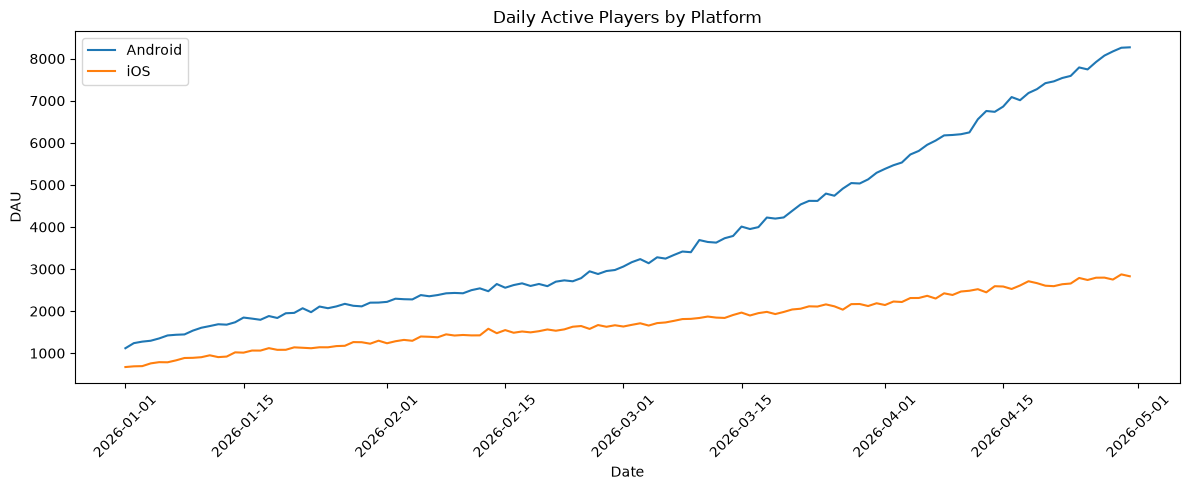

In [19]:
fig, ax = plt.subplots(figsize=(12, 5))

for platform in daily["platform"].dropna().unique():
    tmp = daily[daily["platform"] == platform]
    ax.plot(
        tmp["activity_date"],
        tmp["dau"],
        label=platform
    )

ax.set_title("Daily Active Players by Platform")
ax.set_xlabel("Date")
ax.set_ylabel("DAU")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

fig.savefig(
    CHART_DIR / "daily_dau_by_platform.png",
    dpi=200
)

plt.show()


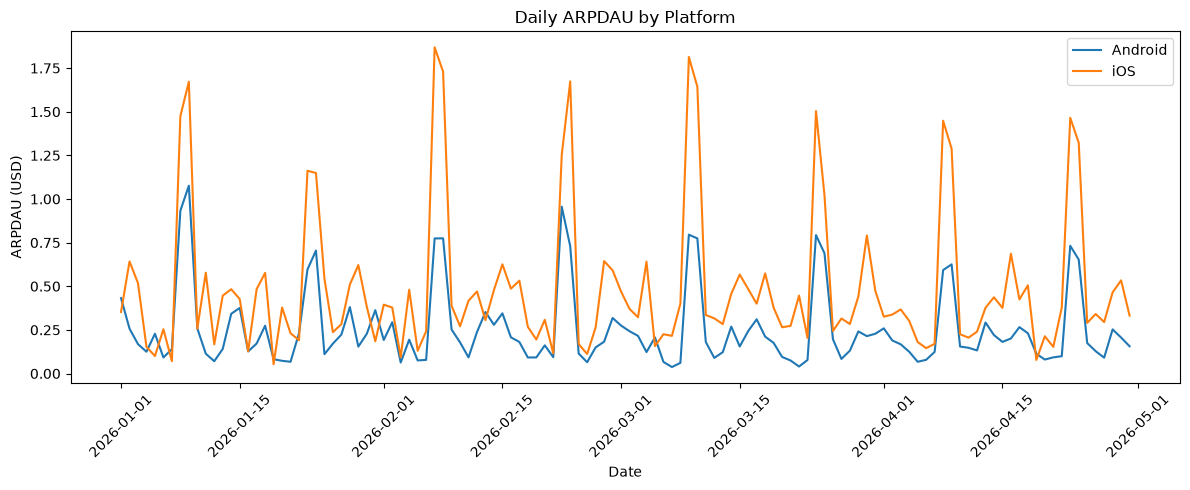

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))

for platform in daily["platform"].dropna().unique():
    tmp = daily[daily["platform"] == platform]
    ax.plot(
        tmp["activity_date"],
        tmp["arpdau"],
        label=platform
    )

ax.set_title("Daily ARPDAU by Platform")
ax.set_xlabel("Date")
ax.set_ylabel("ARPDAU (USD)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

fig.savefig(
    CHART_DIR / "daily_arpdau_by_platform.png",
    dpi=200
)

plt.show()


## 4. Task 1B — Retention

Retention is grouped by install week.

Milestones are D1, D7, D14 and D30. A milestone is calculated only when the player's install date is far enough before 2026-04-30 to observe it.


In [21]:
retention = execute_single_sql("1b_retention.sql")

display(retention)

retention.to_csv(
    TABLE_DIR / "retention.csv",
    index=False
)


,cohort_week,cohort_players,d1_eligible_players,d7_eligible_players,d14_eligible_players,d30_eligible_players,d1_retained_players,d7_retained_players,d14_retained_players,d30_retained_players,d1_retention,d7_retention,d14_retention,d30_retention
0,2025-12-29,1229,1229,1229,1229,1229,565,298,232,157,0.459723,0.242474,0.188771,0.127746
1,2026-01-05,2199,2199,2199,2199,2199,1022,589,421,301,0.464757,0.267849,0.191451,0.136880
2,2026-01-12,2266,2266,2266,2266,2266,1082,594,450,339,0.477493,0.262136,0.198588,0.149603
3,2026-01-19,2234,2234,2234,2234,2234,1066,548,416,283,0.477171,0.245300,0.186213,0.126679
4,2026-01-26,2193,2193,2193,2193,2193,1042,569,470,324,0.475148,0.259462,0.214318,0.147743
5,2026-02-02,2335,2335,2335,2335,2335,1122,627,485,341,0.480514,0.268522,0.207709,0.146039
6,2026-02-09,2262,2262,2262,2262,2262,1141,571,446,330,0.504421,0.252431,0.197171,0.145889
7,2026-02-16,2269,2269,2269,2269,2269,1072,542,442,329,0.472455,0.238872,0.194799,0.144998
8,2026-02-23,2744,2744,2744,2744,2744,1287,734,521,387,0.469023,0.267493,0.189869,0.141035
9,2026-03-02,3241,3241,3241,3241,3241,1542,785,634,432,0.475779,0.242209,0.195619,0.133292


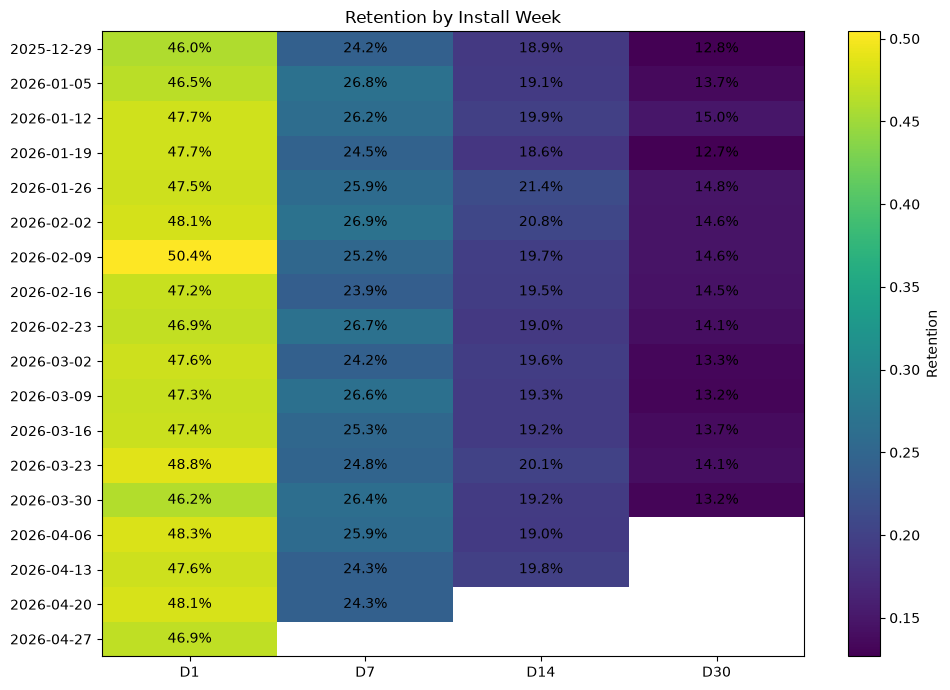

In [22]:
heat = retention.set_index("cohort_week")[
    ["d1_retention", "d7_retention",
     "d14_retention", "d30_retention"]
]

fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    heat.values,
    aspect="auto"
)

ax.set_xticks(range(4))
ax.set_xticklabels(
    ["D1", "D7", "D14", "D30"]
)

ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(
    [str(x)[:10] for x in heat.index]
)

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iloc[i, j]
        if pd.notna(value):
            ax.text(
                j, i,
                f"{value:.1%}",
                ha="center",
                va="center"
            )

ax.set_title("Retention by Install Week")
plt.colorbar(im, ax=ax, label="Retention")
plt.tight_layout()

fig.savefig(
    CHART_DIR / "retention_heatmap.png",
    dpi=200
)

plt.show()


## 5. Task 1C — Spender behaviour

The three requested measures are:

1. Revenue concentration among paying players
2. Time to first purchase, including never-purchasers
3. Gap between consecutive purchases


In [23]:
spender_results = execute_sql_file(
    "1c_spender_behaviour.sql"
)

print("Revenue concentration")
display(spender_results[0])

print("Time to first purchase")
display(spender_results[1].head(20))

print("Repeat purchase gaps")
display(spender_results[2].head(20))


Revenue concentration


,segment,revenue_share
0,Top 1%,0.094409
1,Top 10%,0.480806
2,Top 50%,0.902277


Time to first purchase


,device_id,install_date,first_purchase_date,days_to_first_purchase,purchase_timing_bucket
0,100000,2026-03-05,NaT,<NA>,Never purchased
1,100001,2026-04-09,2026-04-30,21,15-30 days
2,100002,2026-04-10,NaT,<NA>,Never purchased
3,100003,2026-04-08,NaT,<NA>,Never purchased
4,100004,2025-07-02,2026-03-19,260,31+ days
5,100005,2026-03-15,NaT,<NA>,Never purchased
6,100006,2026-03-10,NaT,<NA>,Never purchased
7,100007,2026-03-22,NaT,<NA>,Never purchased
8,100008,2025-09-07,2026-02-28,174,31+ days
9,100009,2025-11-16,NaT,<NA>,Never purchased


Repeat purchase gaps


,device_id,event_ts,previous_purchase_ts,gap_days
0,100164,2026-04-12 09:18:17,2026-04-08 22:19:12,3.457697
1,100282,2026-03-10 16:41:21,2026-01-24 17:58:50,44.946192
2,100282,2026-04-07 17:02:37,2026-03-10 16:41:21,28.014769
3,100307,2026-04-23 21:46:16,2026-02-26 23:59:56,55.907176
4,100308,2026-03-29 08:49:28,2026-03-09 20:04:39,19.531123
5,100314,2026-04-28 18:21:06,2026-04-26 21:17:06,1.877778
6,100351,2026-04-13 22:27:41,2026-04-01 17:16:07,12.216366
7,100351,2026-04-22 18:19:30,2026-04-13 22:27:41,8.827650
8,100353,2026-02-22 07:14:11,2026-01-03 18:40:35,49.523333
9,100374,2026-04-25 16:38:18,2026-04-24 15:59:54,1.026667


In [24]:
spender_results[0].to_csv(
    TABLE_DIR / "revenue_concentration.csv",
    index=False
)

spender_results[1].to_csv(
    TABLE_DIR / "time_to_first_purchase.csv",
    index=False
)

spender_results[2].to_csv(
    TABLE_DIR / "repeat_purchase_gaps.csv",
    index=False
)


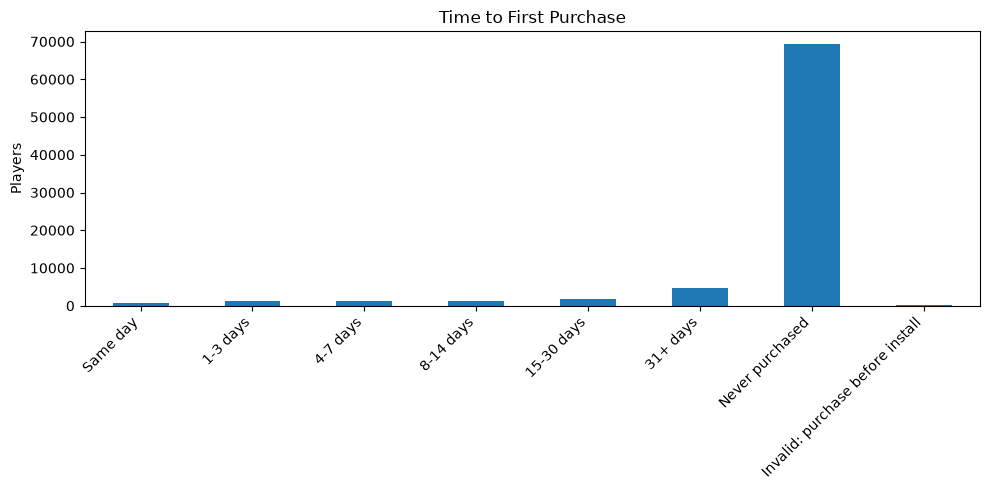

In [25]:
timing = spender_results[1].copy()

bucket_order = [
    "Same day",
    "1-3 days",
    "4-7 days",
    "8-14 days",
    "15-30 days",
    "31+ days",
    "Never purchased",
    "Invalid: purchase before install",
]

bucket_counts = (
    timing["purchase_timing_bucket"]
    .value_counts()
    .reindex(bucket_order)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(10, 5))

bucket_counts.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Time to First Purchase")
ax.set_xlabel("")
ax.set_ylabel("Players")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

fig.savefig(
    CHART_DIR / "time_to_first_purchase.png",
    dpi=200
)

plt.show()


## 6. Task 1D — Rewarded ads

Primary definition:

**Ad-watching player-day** = a player-day with at least one completed ad.

**Cap hit** = maximum recorded `ad_daily_count` is greater than or equal to `ad_daily_cap`.


In [26]:
ad_results = execute_sql_file(
    "1d_rewarded_ads.sql"
)

print("Cap-hit rate")
display(ad_results[0])

print("Daily ad views")
display(ad_results[1].head(20))


Cap-hit rate


,ad_daily_cap,ad_watching_player_days,cap_hit_player_days,cap_hit_share
0,5,294776,3026.0,0.010265
1,8,102049,13.0,0.000127


Daily ad views


,activity_date,total_ad_events,completed_ad_views,started_events,abandoned_events
0,2026-01-01,536,443,22,71
1,2026-01-02,1648,1363,81,204
2,2026-01-03,1834,1533,76,225
3,2026-01-04,1811,1491,84,236
4,2026-01-05,1870,1535,106,229
5,2026-01-06,1935,1580,103,252
6,2026-01-07,2032,1671,109,252
7,2026-01-08,2098,1755,93,250
8,2026-01-09,2178,1773,118,287
9,2026-01-10,2118,1753,122,243


In [27]:
ad_results[0].to_csv(
    TABLE_DIR / "ad_cap_hit_rate.csv",
    index=False
)

ad_results[1].to_csv(
    TABLE_DIR / "daily_ad_views.csv",
    index=False
)


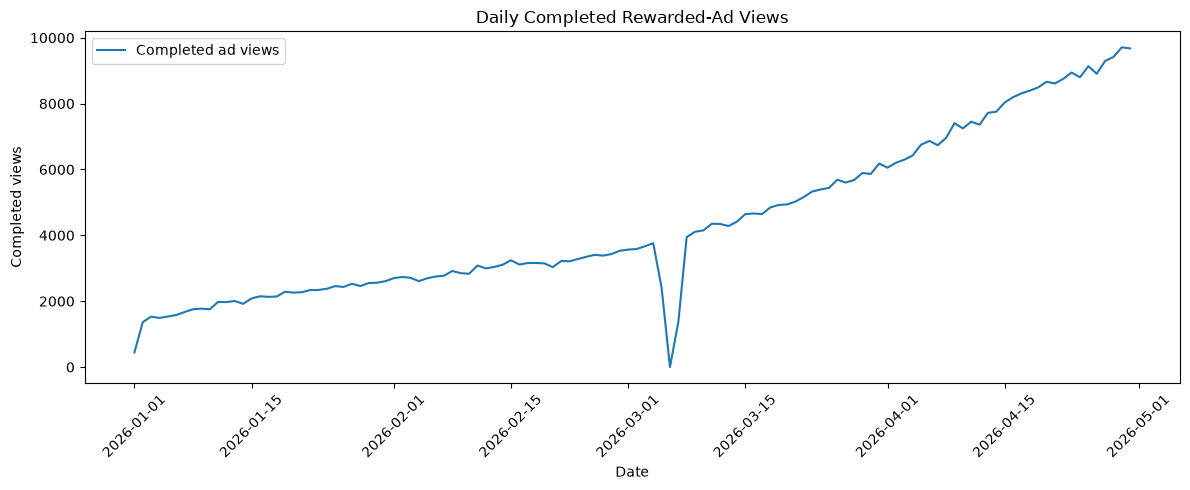

In [28]:
daily_ads = ad_results[1].copy()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_ads["activity_date"],
    daily_ads["completed_ad_views"],
    label="Completed ad views"
)

ax.set_title("Daily Completed Rewarded-Ad Views")
ax.set_xlabel("Date")
ax.set_ylabel("Completed views")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()

fig.savefig(
    CHART_DIR / "daily_completed_ad_views.png",
    dpi=200
)

plt.show()


## 7. Task 1 findings

Fill these after reviewing the outputs.

### Daily health
- DAU trend:
- Revenue trend:
- ARPDAU trend:
- Purchase-rate trend:

### Retention
- D1:
- D7:
- D14:
- D30:
- Cohort trend:

### Spender behaviour
- Top 1% revenue share:
- Top 10% revenue share:
- Top 50% revenue share:
- Never-purchase share:
- Repeat-purchase gap:

### Rewarded ads
- Overall cap-hit share:
- Cap-specific pattern:
- Daily ad-view anomaly:

### Data quality
- Main issue:
- Treatment:
- Remaining uncertainty:


## 8. Task 1 output files

The notebook saves:

- `output/tables/daily_health.csv`
- `output/tables/retention.csv`
- `output/tables/revenue_concentration.csv`
- `output/tables/time_to_first_purchase.csv`
- `output/tables/repeat_purchase_gaps.csv`
- `output/tables/ad_cap_hit_rate.csv`
- `output/tables/daily_ad_views.csv`

Charts are saved under `output/charts/`.
